# **BERTopic on Large Datasets**: Modified Notebook from the Template of Maarten Grootendorst

Grootendorst: Due to the modularity of BERTopic, it can also be used on large datasets (> 1_000_000) if we change some of the internal algorithms such that they can scale a bit better.

To do so, this example uses Google Colab Pro (T4 with 25GB of VRAM and 26GB of System RAM) and cuML to enable GPU-accelerated machine learning.

First, we will need to install some packages:

In [ ]:
# Mounts the GDrive to access the data
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%%capture
!pip install git+https://github.com/MaartenGr/BERTopic.git@master
!pip install openai
# !pip install datamapplot
# !pip install urlextract

!pip install cudf-cu12 dask-cudf-cu12 --extra-index-url=https://pypi.nvidia.com
!pip install cuml-cu12 --extra-index-url=https://pypi.nvidia.com
!pip install cugraph-cu12 --extra-index-url=https://pypi.nvidia.com
!pip install cupy-cuda12x -f https://pip.cupy.dev/aarch64

# !git clone https://github.com/jparksecurity/rapidsai-csp-utils.git
# !git clone https://github.com/rapidsai/rapidsai-csp-utils.git
# !python rapidsai-csp-utils/colab/pip-install.py

!pip install safetensors
# !pip install datasets
# !pip install datashader
!pip install adjustText

In [ ]:
import cuml
cuml.__version__

'23.12.00'

Tweet data is at: './content/drive/MyDrive/data_tr'

# **Data**

In this part, the collected and hydrated tweet data is loaded

In [ ]:
import os
import re
import warnings
import pandas as pd
import json
import logging
import numpy as np
from concurrent.futures import ThreadPoolExecutor
# import dask.dataframe as dd
import datetime
import glob
from bertopic import BERTopic

In [ ]:
import torch
print(torch.cuda.is_available())

True


In [ ]:
# Loggings
warnings.filterwarnings(action='ignore', category=FutureWarning)

# Configure logging to write to a file and the console
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(name)s - %(levelname)s - %(message)s',
    handlers=[
        logging.FileHandler(filename='/content/drive/MyDrive/data_tr/analysis.log'),
        logging.StreamHandler()
    ]
)

In [ ]:
!pwd

/content


In [ ]:
# 'folder_name' is also used to save the topic modeling results
folder_name = "3-streamV2_tweetids_2023-06_splitted"
input_folder_path = f'/content/drive/MyDrive/data_tr/tweetnet/{folder_name}/'

### Data read & preprocessing
Altough the first approach used to read the hydrated tweet data from csv file and preprocess the tweets in this notebook, the second approach prepress the tweets on the Social5 server and then imports the data directly as list of strings to pass them to the analysis part.

In [ ]:
def extract_number(filename):
    # Regular expression to match a sequence of digits
    match = re.search(r'_(\d+)\.csv$', filename)
    return int(match.group(1)) if match else 0

# Function to clean or convert 'tweet_id'
def clean_tweet_id(val):
    try:
        return int(val)  # Convert to integer if possible
    except ValueError:
        return pd.NA  # Use Pandas NA for missing values

In [ ]:
all_files = glob.glob(os.path.join(input_folder_path, '*.csv'), recursive=True)

# Create a list to hold DataFrames
sorted_files = sorted(all_files, key=extract_number)

In [ ]:
# investigate

def read_csv_file(file_path):
    try:
        df = pd.read_csv(file_path, usecols=['tweet_id', 'text', 'tweet_type'], error_bad_lines=False, warn_bad_lines=True)
        # df = df[~df['tweet_id'].isin(training_tweet_ids)] #TODO change this line
        return df
    except pd.errors.ParserError as e:
        print(f"Error in file: {file_path}")
        print(e)
        return pd.DataFrame()  # Return an empty DataFrame in case of error

df = pd.concat([read_csv_file(file) for file in sorted_files], ignore_index=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11180109 entries, 0 to 11180108
Data columns (total 3 columns):
 #   Column      Dtype 
---  ------      ----- 
 0   tweet_id    object
 1   tweet_type  object
 2   text        object
dtypes: object(3)
memory usage: 255.9+ MB


In [ ]:
df = df[['tweet_id', 'text']]
# Apply the cleaning function to 'tweet_id'
df['tweet_id'] = df['tweet_id'].map(clean_tweet_id)
# Drop NaN values from 'text' column and persist
df = df.dropna(subset=['text'])
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 6327124 entries, 7 to 11180108
Data columns (total 2 columns):
 #   Column    Dtype 
---  ------    ----- 
 0   tweet_id  object
 1   text      object
dtypes: object(2)
memory usage: 144.8+ MB


In [ ]:
docs = df["text"].tolist()
docs = [doc for doc in docs if pd.notnull(doc) and doc != '']

In [ ]:
# import pickle
# # Save the list to a file
# with open('/content/drive/MyDrive/data_tr/docs.pkl', 'wb') as file:
#     pickle.dump(docs, file)

Read the sample data, which is used to train the base topic model:

In [ ]:
# Load the list from the file
# import pickle
# with open('/content/drive/MyDrive/data_tr/docs_05_06.pkl', 'rb') as file:
#     loaded_list = pickle.load(file)
# docs = loaded_list

In [ ]:
# Load from CSV
sampled_tweets_df = pd.read_csv('/content/drive/MyDrive/data_tr/tweet_sample_2.csv')
docs = sampled_tweets_df['text'].tolist()

Read the preprocessed text, which is used in topic modeling analysis:

In [ ]:
import pickle

# Reading the data from the pickle file
with open(f'/content/drive/MyDrive/data_tr/lists/{folder_name}.pkl', 'rb') as file:
    docs = pickle.load(file)

## Preprocessing Part

Preprocessing from TurkishBERTweet paper. See: https://huggingface.co/VRLLab/TurkishBERTweet

In [ ]:
# from Preprocessor import preprocess

# text = """Lab'ımıza "viral" adını verdik çünkü amacımız disiplinler arası sınırları aşmak ve aralarında yeni bağlantılar kurmak! 🔬 #ViralLab
# https://varollab.com/"""

# preprocessed_text = preprocess(text)
# print(preprocessed_text)

# **The BERTopic Pipeline**

Now that we have our data, we can start with the analysis. This part is explained in the thesis in detail.

## Embeddings

Next, we are going to pre-calculate the embeddings as input for our BERTopic model. The reason for doing this is that this input step can take quite some time to compute. If we pre-calculate them and save the resulting embeddings, we can skip over this step when we are iterating over our model. (Grootendorst)

In [ ]:
# !pip install -U sentence-transformers
from sentence_transformers import SentenceTransformer

# Create embeddings
embedding_model = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.12k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/471M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

1_Pooling/config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
embeddings = embedding_model.encode(docs, show_progress_bar=True)

Batches:   0%|          | 0/76079 [00:00<?, ?it/s]

We can save the resulting embeddings as follows:

In [ ]:
# Get the current date and time
current_time = datetime.datetime.now()

# Format the date and time in the desired format (e.g., 'YYYYMMDD_HHMMSS')
timestamp = current_time.strftime('%Y%m%d_%H%M%S')

# file_name = f'/content/drive/MyDrive/data_tr/embeddings/embeddings_sample_tweets_v2_{folder_name}_{timestamp}.npy'
file_name = f'/content/drive/MyDrive/data_tr/embeddings/embeddings_sample_tweets_v4_{timestamp}.npy'

with open(file_name, 'wb') as f:
    np.save(f, embeddings)

and then load the embeddings as follows:

In [ ]:
loaded_embeddings_big = np.load('/content/drive/MyDrive/data_tr/embeddings/embeddings_sample_tweets_v3_20240116_101435.npy')

## Prepare Vocab

Before we can start with training our model, there is still something that we can do to reduce the necessary memory. We can prepare our vocabulary beforehand such that the tokenizer does not need to do the calculations itself.

Below, we are essentially creating a vocabulary of words in our dataset and parsing them such that they need to appear at least 10 times in our data.

With sufficient RAM, we could skip over this step but Grootendorst have found this often helps in reducing the necessary RAM. (Grootendorst)

The Turkish stopwords from the NLTK library are passed to the CountVectorizer.

In [ ]:
import collections
from tqdm import tqdm
from sklearn.feature_extraction.text import CountVectorizer

# Extract vocab to be used in BERTopic
vocab = collections.Counter()
tokenizer = CountVectorizer().build_tokenizer()
for doc in tqdm(docs):
  vocab.update(tokenizer(doc))
vocab = [word for word, frequency in vocab.items() if frequency >= 10]; len(vocab)

100%|██████████| 2434498/2434498 [00:37<00:00, 65048.50it/s]


146271

In [ ]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')
stopwords.words('turkish')

## Train BERTopic

Finally, we can train the base BERTopic model. We select the same sentence-transformer model as we did before ('paraphrase-multilingual-MiniLM-L12-v2'). Moreover, cuML's HDBSCAN and UMAP models are used, which are GPU-accelerated versions of HDBSCAN and UMAP and allow to speed training on such a large dataset.

As topic representation models, KeyBERTInspired and MMR models have been used. However, after the transformation process, GPT-4 Turbo model from OpenAI has been used for the top 50 topics.

In [ ]:
from bertopic.representation import KeyBERTInspired, MaximalMarginalRelevance

# KeyBERT
keybert_model = KeyBERTInspired()

# MMR
mmr_model = MaximalMarginalRelevance(diversity=0.3)

# from google.colab import userdata
# client = openai.OpenAI(api_key=userdata.get('OPENAI_KEY'))

# All representation models
representation_model = {
    "KeyBERT": keybert_model,
    # "OpenAI": openai_model,
    "MMR": mmr_model,
}

In [ ]:
from cuml.manifold import UMAP
from cuml.cluster import HDBSCAN
# from umap import UMAP
# from hdbscan import HDBSCAN
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer

# Prepare sub-models
embedding_model = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')
umap_model = UMAP(n_components=5, n_neighbors=25, random_state=42, metric="cosine", verbose=True)

hdbscan_model = HDBSCAN(min_samples=20, gen_min_span_tree=True, prediction_data=True, min_cluster_size=100, verbose=True)
# min_cluster_size: https://hdbscan.readthedocs.io/en/latest/parameter_selection.html
# min_samples: setting this lower then min_cluster_size would help to reduce the outliers (Grootendorst)
vectorizer_model = CountVectorizer(vocabulary=vocab, stop_words=stopwords.words('turkish'), ngram_range=(1, 2))

# Fit BERTopic without actually performing any clustering
topic_model= BERTopic(
        embedding_model=embedding_model,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model,
        representation_model=representation_model,
        verbose=True,
        min_topic_size=1000,# is not used since hdbscan is used and this params is set to the same value with "min_cluster_size"
).fit(docs, embeddings=loaded_embeddings_big)

2024-01-16 11:43:32,064 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm


[D] [11:43:35.308917] /__w/cuml/cuml/cpp/src/umap/runner.cuh:108 n_neighbors=25
[D] [11:43:35.309923] /__w/cuml/cuml/cpp/src/umap/runner.cuh:130 Calling knn graph run
[D] [12:13:01.323957] /__w/cuml/cuml/cpp/src/umap/runner.cuh:136 Done. Calling fuzzy simplicial set
[D] [12:13:01.403922] /__w/cuml/cuml/cpp/src/umap/fuzzy_simpl_set/naive.cuh:317 Smooth kNN Distances
[D] [12:13:01.407113] /__w/cuml/cuml/cpp/src/umap/fuzzy_simpl_set/naive.cuh:319 sigmas = [ 0.0173853, 0.00266452, 1.19209e-10, 6.47015e-08, 0.104194, 0.0121175, 0.0149226, 0.00433409, 0.207896, 0.031037, 0.0211208, 0.113371, 0.000121294, 0.00176777, 0.0116453, 0.0205189, 0.0115315, 0.0761669, 0.0415357, 0.0722303, 0.014417, 0.025111, 0.00925517, 0.0205227, 0.00892103 ]

[D] [12:13:01.407170] /__w/cuml/cuml/cpp/src/umap/fuzzy_simpl_set/naive.cuh:321 rhos = [ 0.0884956, 0.247238, 1.19209e-07, 1.78814e-07, 1.78814e-07, 0.058448, 0.257719, 0.135435, 2.98023e-07, 0.252859, 0.119825, 2.38419e-07,    0, 2.98023e-07, 0.135407, 0.100

2024-01-16 12:44:53,561 - BERTopic - Dimensionality - Completed ✓
2024-01-16 12:44:53,627 - BERTopic - Cluster - Start clustering the reduced embeddings
2024-01-16 13:05:02,278 - BERTopic - Cluster - Completed ✓
2024-01-16 13:05:02,916 - BERTopic - Representation - Extracting topics from clusters using representation models.
/usr/local/lib/python3.10/dist-packages/bertopic/vectorizers/_ctfidf.py:82: RuntimeWarning: divide by zero encountered in divide
  idf = np.log((avg_nr_samples / df)+1)
2024-01-16 13:07:53,610 - BERTopic - Representation - Completed ✓


and that is it! We can inspect the topics as follows:

In [ ]:
topic_model.get_topic_info()

Lastly, the model is saved as follows:

In [ ]:
import datetime

# Get the current date and time
current_time = datetime.datetime.now()

# Format the date and time in the desired format (e.g., 'YYYYMMDD_HHMMSS')
timestamp = current_time.strftime('%Y%m%d_%H%M%S')
output_model_path = f'/content/drive/MyDrive/data_tr/models/model_{timestamp}'
os.makedirs(output_model_path, exist_ok=True)


In [ ]:
topic_model.save(
    path=output_model_path,
    serialization="safetensors",
    save_ctfidf=True,
    save_embedding_model="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

And loaded as follows:

In [ ]:
loaded_model = BERTopic.load("/content/drive/MyDrive/data_tr/models/model_20231220_165725", embedding_model=embedding_model)

Here the topic model results of the first approach are presented (before transforming the rest of the data):

In [ ]:
loaded_model.get_topic_info()

,Topic,Count,Name,Representation,KeyBERT,MMR,Representative_Docs
0,-1,1646514,-1_chp_parti_aday_kılıçdaroğlu,"[chp, parti, aday, kılıçdaroğlu, the, muharrem...","[muharrem, başkan, muhalefet, diyor, milletvek...","[chp, parti, aday, kılıçdaroğlu, the, muharrem...",NaN
1,0,58799,0_aysedogan1955_yirmiucderece_hassa61_furkance...,"[aysedogan1955, yirmiucderece, hassa61, furkan...","[ahmet_davutoglu, hayati_yazici, haberalp1, mu...","[aysedogan1955, yirmiucderece, hassa61, furkan...",NaN
2,1,28996,1_allah_versin_eylesin_müslüman,"[allah, versin, eylesin, müslüman, razı, mekan...","[allahu, الله, allah, rahmet, peygamber, namaz...","[allah, versin, eylesin, müslüman, razı, mekan...",NaN
3,2,27236,2_türk_turkey_türkiye_yüzyılı,"[türk, turkey, türkiye, yüzyılı, türkiyeyüzyıl...","[türklüğü, türkiyede, türkçü, turkish, türk, t...","[türk, turkey, türkiye, yüzyılı, türkiyeyüzyıl...",NaN
4,3,21908,3_oy_kılıçdaroğlu_oyları_seçmeni,"[oy, kılıçdaroğlu, oyları, seçmeni, oylar, ver...","[oylarını, adaylığını, aday, adaylıktan, oylar...","[oy, kılıçdaroğlu, oyları, seçmeni, oylar, ver...",NaN
...,...,...,...,...,...,...,...
7586,7585,20,7585_gücümüzün_emeğimizin_haklıyız_sebeple,"[gücümüzün, emeğimizin, haklıyız, sebeple, tar...","[emeğimizin, vedatbilgn, stajsskbaşlangıcıolsu...","[gücümüzün, emeğimizin, haklıyız, sebeple, tar...",NaN
7587,7586,20,7586_bellshabercom_verek_laaan_değişir,"[bellshabercom, verek, laaan, değişir, kopya, ...","[bellshabercom, küfür, artık, göre, lütfen, kr...","[bellshabercom, verek, laaan, değişir, kopya, ...",NaN
7588,7587,20,7587_432_depremzedeyi_katarak_gündüzüne,"[432, depremzedeyi, katarak, gündüzüne, itfaiy...","[itfaiyeci, kurtaran, depremzedeyi, kutluyorum...","[432, depremzedeyi, katarak, gündüzüne, itfaiy...",NaN
7589,7588,20,7588_sahapkavcioglu_vakifbank_evkaf_trwealthfund,"[sahapkavcioglu, vakifbank, evkaf, trwealthfun...","[sahapkavcioglu, aliihsanyavuz54, hkemalkurt, ...","[sahapkavcioglu, vakifbank, evkaf, trwealthfun...",NaN


In [ ]:
loaded_model.get_topic_info(7323)

,Topic,Count,Name,Representation,KeyBERT,MMR,Representative_Docs
0,7323,21,7323_erbakancayazan_örneğinde_yolunuzdan_iddialar,"[erbakancayazan, örneğinde, yolunuzdan, iddial...","[muhalefetten, siyasetci, partiyi, edenlerin, ...","[erbakancayazan, örneğinde, yolunuzdan, iddial...",NaN


In [ ]:
updated_model = BERTopic.load("/content/drive/MyDrive/data_tr/models/updated_model", embedding_model=embedding_model)
updated_model.get_topic_info()

,Topic,Count,Name,Representation,KeyBERT,MMR,Representative_Docs
0,0,91644,0_yirmiucderece_aykiricomtr_furkancerkes_pusho...,"[yirmiucderece, aykiricomtr, furkancerkes, pus...","[ahmet_davutoglu, hayati_yazici, haberalp1, mu...","[aysedogan1955, yirmiucderece, hassa61, furkan...",NaN
1,1,38853,1_allah_eylesin_versin_razı,"[allah, eylesin, versin, razı, mekanı, müslüma...","[allahu, الله, allah, rahmet, peygamber, namaz...","[allah, versin, eylesin, müslüman, razı, mekan...",NaN
2,2,47628,2_türk_türkiye_stanbul_turkey,"[türk, türkiye, stanbul, turkey, cumhuriyeti, ...","[türklüğü, türkiyede, türkçü, turkish, türk, t...","[türk, turkey, türkiye, yüzyılı, türkiyeyüzyıl...",NaN
3,3,52813,3_oy_oyları_seçmeni_oylar,"[oy, oyları, seçmeni, oylar, kılıçdaroğlu, seç...","[oylarını, adaylığını, aday, adaylıktan, oylar...","[oy, kılıçdaroğlu, oyları, seçmeni, oylar, ver...",NaN
4,4,17287,4_emeklilik_kısmi_kademeli_emekli,"[emeklilik, kısmi, kademeli, emekli, emeklilik...","[emeklilikteyaşatakılanlar, emeklilere, emekli...","[emeklilik, kısmi, kademeli, emekli, emeklilik...",NaN
...,...,...,...,...,...,...,...
7585,7585,72,7585_gücümüzün_haklıyız_tarihimiz_emeğimizin,"[gücümüzün, haklıyız, tarihimiz, emeğimizin, p...","[emeğimizin, vedatbilgn, stajsskbaşlangıcıolsu...","[gücümüzün, emeğimizin, haklıyız, sebeple, tar...",NaN
7586,7586,118,7586_bellshabercom_belliydi_demicem_جدا,"[bellshabercom, belliydi, demicem, جدا, bisi, ...","[bellshabercom, küfür, artık, göre, lütfen, kr...","[bellshabercom, verek, laaan, değişir, kopya, ...",NaN
7587,7587,36,7587_djziqbvwde_432_depremzedeyi_itfaiye,"[djziqbvwde, 432, depremzedeyi, itfaiye, katar...","[itfaiyeci, kurtaran, depremzedeyi, kutluyorum...","[432, depremzedeyi, katarak, gündüzüne, itfaiy...",NaN
7588,7588,356,7588_vakifbank_sahinkorkmaz06_tazelendi_bddkresmi,"[vakifbank, sahinkorkmaz06, tazelendi, bddkres...","[sahapkavcioglu, aliihsanyavuz54, hkemalkurt, ...","[sahapkavcioglu, vakifbank, evkaf, trwealthfun...",NaN


In [ ]:
updated_model_pandas = updated_model.get_topic_info()
updated_model_pandas.to_csv('/content/drive/MyDrive/data_tr/results/updated_model_csv.csv', index=False)

### Transforming the remaining data using the base topic model

In [ ]:
# Define embedding model
embedding_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

# Load the base model
loaded_model = BERTopic.load("/content/drive/MyDrive/data_tr/models/model_20240114_182239", embedding_model=embedding_model)
# loaded_model = BERTopic.load("/content/drive/MyDrive/data_tr/models/model_20240116_130759", embedding_model=embedding_model)

In [ ]:
chunk_size = 30000  # Adjust based on the dataset and memory constraints

# Divide the documents into four equal parts
quarter_length = len(docs) // 4
quarters = [docs[i:i + quarter_length] for i in range(0, len(docs), quarter_length)]

# Initialize a dictionary to store topics for each quarter
quarterly_topics = {}

# Process each quarter in batches
for quarter_index, quarter_docs in enumerate(quarters):
    quarter_topics = []
    total_chunks = len(quarter_docs) // chunk_size + (1 if len(quarter_docs) % chunk_size != 0 else 0)

    logging.info(f"Processing Quarter {quarter_index+1}, Total Chunks: {total_chunks}")
    print(f"Processing Quarter {quarter_index+1}, Total Chunks: {total_chunks}")

    for i in range(0, len(quarter_docs), chunk_size):
        chunk_num = i // chunk_size + 1
        logging.info(f"Processing chunk {chunk_num} of {total_chunks} in Quarter {quarter_index+1}")
        print(f"Processing chunk {chunk_num} of {total_chunks} in Quarter {quarter_index+1}")

        # Extract a chunk of documents
        doc_chunk = quarter_docs[i:i + chunk_size]

        # Create embeddings for the chunk
        chunk_embeddings = embedding_model.encode(doc_chunk, show_progress_bar=True)

        # Transform the chunk to get topic distributions
        chunk_new_topics, chunk_new_probs = loaded_model.transform(doc_chunk, embeddings=chunk_embeddings)

        # Store the results for this chunk
        quarter_topics.extend(chunk_new_topics)

    # Store the aggregated results for this quarter
    quarterly_topics[f"Quarter {quarter_index+1}"] = quarter_topics
    logging.info(f"Completed processing for Quarter {quarter_index+1}")

# Now, quarterly_topics contains the topic information for each quarter

And save the transformed data as follows. 

This method assigns each tweet a topic. These are then used in the analysis part.

In [ ]:
output_topics_path = f'/content/drive/MyDrive/data_tr/analyzed_v2/{folder_name}'
os.makedirs(output_topics_path, exist_ok=True)

for quarter, topics in quarterly_topics.items():
    quarter_docs = quarters[int(quarter.split(' ')[1]) - 1]
    df = pd.DataFrame({'Document': quarter_docs[:len(topics)], 'Topic': topics})
    df.to_csv(f'{output_topics_path}/{quarter}_topic_assignments.csv', index=False)

# Analysis

In [ ]:
df_old_topics = loaded_model.get_topic_info()
# df_old_topics.to_csv('/content/drive/MyDrive/data_tr/results_v2/first_topics.csv', index=False)

In [ ]:
df_to_analyze = loaded_model.get_document_info(docs)
docs_to_analyze = df_to_analyze["Document"].tolist()
topics_to_analyze = df_to_analyze["Topic"].tolist()

Here the topic model results of the **second** approach are presented (before transforming the rest of the data):

In [ ]:
loaded_model.get_topic_info()

,Topic,Count,Name,Representation,KeyBERT,MMR,Representative_Docs
0,-1,1779223,-1_co_https_bir_rterdogan,"[co, https, bir, rterdogan, dbdevletbahceli, a...","[yilmaz_ismet58, uzmançavuşlartorbayasaya, erb...","[co, https, bir, rterdogan, dbdevletbahceli, a...",NaN
1,0,92996,0_oy_kılıçdaroğlu_aday_seçim,"[oy, kılıçdaroğlu, aday, seçim, erdoğan, tayyi...","[verecek, erdoğana, muharrem, oldu, kemal, olu...","[oy, kılıçdaroğlu, aday, seçim, erdoğan, tayyi...",NaN
2,1,30870,1_türk_türkiye_stanbul_yüzyılı,"[türk, türkiye, stanbul, yüzyılı, turkey, türk...","[türkiyede, türkçü, turkish, türkiyeyi, türk, ...","[türk, türkiye, stanbul, yüzyılı, turkey, türk...",NaN
3,2,26819,2_öğretmen_öğretmenler_tcmeb_ataması,"[öğretmen, öğretmenler, tcmeb, ataması, prof_m...","[öğretmenlere, öğretmenleri, öğretmenler, öğre...","[öğretmen, öğretmenler, tcmeb, ataması, prof_m...",NaN
4,3,22736,3_deprem_depremde_depremzede_depremin,"[deprem, depremde, depremzede, depremin, yapık...","[depremzedelere, depremzedeleri, depremzedeler...","[deprem, depremde, depremzede, depremin, yapık...",NaN
...,...,...,...,...,...,...,...
1141,1140,100,1140_endangered_across_rights_human,"[endangered, across, rights, human, democracy,...","[hatred, twitter, against, violence, she, demo...","[endangered, across, rights, human, democracy,...",NaN
1142,1141,100,1141_yatırın_yönetin_öğreteceğiz_görevlendirilen,"[yatırın, yönetin, öğreteceğiz, görevlendirile...","[öğreteceğiz, görevlendirilen, maaş, çalışan, ...","[yatırın, yönetin, öğreteceğiz, görevlendirile...",NaN
1143,1142,100,1142_nolu_sandık_geçersiz_oğan,"[nolu, sandık, geçersiz, oğan, nce, köyü, sonu...","[erkan, dördüncü, erdoğan, sonuçları, kufeoglu...","[nolu, sandık, geçersiz, oğan, nce, köyü, sonu...",NaN
1144,1143,100,1143_erkek_önlisans_onlisanspomem15bin_kontenj...,"[erkek, önlisans, onlisanspomem15bin, kontenja...","[adaylara, adaylarının, adayların, adayları, a...","[erkek, önlisans, onlisanspomem15bin, kontenja...",NaN


Here the topic model results of an approach, in which the tweets are preprocessed beforehand, are presented. This approach is not used for the analysis and not mentioned in the thesis.

One can see that preprocessed words like "user, http, co, emoji, hashtag" makes the top representative words of the trending topics.

In [ ]:
loaded_model.get_topic_info()

,Topic,Count,Name,Representation,KeyBERT,MMR,Representative_Docs
0,-1,2875,-1_soframızı_büyütmeye_sabırla_sesleniş,"[soframızı, büyütmeye, sabırla, sesleniş, kâh,...","[edeceğiz, birleşeceğiz, büyütmeye, artıracak,...","[soframızı, büyütmeye, sabırla, sesleniş, kâh,...",NaN
1,0,771161,0_uzmançavuşlartorbayasaya_hashtag_uzman_kadro,"[uzmançavuşlartorbayasaya, hashtag, uzman, kad...","[hashtag, canverenlertorbayasaya, http, caneke...","[uzmançavuşlartorbayasaya, hashtag, uzman, kad...",NaN
2,1,86238,1_user_http_bir_co,"[user, http, bir, co, the, emoji, hashtag, say...","[user, http, hashtag, co, sen, mi, tek, oy, ol...","[user, http, bir, co, the, emoji, hashtag, say...",NaN
3,2,80959,2_user_hashtag_istiyoruz_bir,"[user, hashtag, istiyoruz, bir, emoji, http, a...","[user, http, cumhurbaşkanım, cumhurbaşkanı, oy...","[user, hashtag, istiyoruz, bir, emoji, http, a...",NaN
4,3,79979,3_sen_bir_adam_kemal,"[sen, bir, adam, kemal, kılıçdaroğlu, emoji, u...","[user, http, sende, sizi, benim, co, kendi, ol...","[sen, bir, adam, kemal, kılıçdaroğlu, emoji, u...",NaN
...,...,...,...,...,...,...,...
621,620,100,620_gidiyoruz_bedeli_200_tık,"[gidiyoruz, bedeli, 200, tık, çarpışma, anladi...","[sağa_bakan_yumruk_koyu_ten_tonu, daniştay, be...","[gidiyoruz, bedeli, 200, tık, çarpışma, anladi...",NaN
622,621,100,621_ekodemehakkimiz_bağkurdan_hekim_diş,"[ekodemehakkimiz, bağkurdan, hekim, diş, hekim...","[dişhekimlerinin, emeklisi, emekli, ödeme, hek...","[ekodemehakkimiz, bağkurdan, hekim, diş, hekim...",NaN
623,622,100,622_militar_stajyerhakpeşinde_bmağduru_ytgelir...,"[militar, stajyerhakpeşinde, bmağduru, ytgelir...","[tuş_başlığı_rakam_sıfır, yikilmadi, oyyok, ye...","[militar, stajyerhakpeşinde, bmağduru, ytgelir...",NaN
624,623,100,623_birleşeceğiz_kazanacağız_kime_karşı,"[birleşeceğiz, kazanacağız, kime, karşı, http,...","[kazanacağız, birleşeceğiz, karşı, http, co, ,...","[birleşeceğiz, kazanacağız, kime, karşı, http,...",NaN


In [ ]:
mmr_topic_labels = {topic: " | ".join(list(zip(*values))[0][:4]) for topic, values in loaded_model.topic_aspects_["MMR"].items()}
loaded_model.set_topic_labels(mmr_topic_labels)

In [ ]:
updated_model = BERTopic.load("/content/drive/MyDrive/data_tr/models/updated_model", embedding_model=embedding_model)

In [ ]:
loaded_embeddings_2d = np.load('/content/drive/MyDrive/data_tr/embeddings/reduced_embeddings_2d_sample_tweets_20231220_175836.npy')

The CustomName column has been set using the top four words from the MMR representation model.

In [ ]:
loaded_model.get_topic_info()

,Topic,Count,Name,CustomName,Representation,KeyBERT,MMR,Representative_Docs
0,-1,1779223,-1_co_https_bir_rterdogan,co | https | bir | rterdogan,"[co, https, bir, rterdogan, dbdevletbahceli, a...","[yilmaz_ismet58, uzmançavuşlartorbayasaya, erb...","[co, https, bir, rterdogan, dbdevletbahceli, a...",NaN
1,0,92996,0_oy_kılıçdaroğlu_aday_seçim,oy | kılıçdaroğlu | aday | seçim,"[oy, kılıçdaroğlu, aday, seçim, erdoğan, tayyi...","[verecek, erdoğana, muharrem, oldu, kemal, olu...","[oy, kılıçdaroğlu, aday, seçim, erdoğan, tayyi...",NaN
2,1,30870,1_türk_türkiye_stanbul_yüzyılı,türk | türkiye | stanbul | yüzyılı,"[türk, türkiye, stanbul, yüzyılı, turkey, türk...","[türkiyede, türkçü, turkish, türkiyeyi, türk, ...","[türk, türkiye, stanbul, yüzyılı, turkey, türk...",NaN
3,2,26819,2_öğretmen_öğretmenler_tcmeb_ataması,öğretmen | öğretmenler | tcmeb | ataması,"[öğretmen, öğretmenler, tcmeb, ataması, prof_m...","[öğretmenlere, öğretmenleri, öğretmenler, öğre...","[öğretmen, öğretmenler, tcmeb, ataması, prof_m...",NaN
4,3,22736,3_deprem_depremde_depremzede_depremin,deprem | depremde | depremzede | depremin,"[deprem, depremde, depremzede, depremin, yapık...","[depremzedelere, depremzedeleri, depremzedeler...","[deprem, depremde, depremzede, depremin, yapık...",NaN
...,...,...,...,...,...,...,...,...
1141,1140,100,1140_endangered_across_rights_human,endangered | across | rights | human,"[endangered, across, rights, human, democracy,...","[hatred, twitter, against, violence, she, demo...","[endangered, across, rights, human, democracy,...",NaN
1142,1141,100,1141_yatırın_yönetin_öğreteceğiz_görevlendirilen,yatırın | yönetin | öğreteceğiz | görevlendirilen,"[yatırın, yönetin, öğreteceğiz, görevlendirile...","[öğreteceğiz, görevlendirilen, maaş, çalışan, ...","[yatırın, yönetin, öğreteceğiz, görevlendirile...",NaN
1143,1142,100,1142_nolu_sandık_geçersiz_oğan,nolu | sandık | geçersiz | oğan,"[nolu, sandık, geçersiz, oğan, nce, köyü, sonu...","[erkan, dördüncü, erdoğan, sonuçları, kufeoglu...","[nolu, sandık, geçersiz, oğan, nce, köyü, sonu...",NaN
1144,1143,100,1143_erkek_önlisans_onlisanspomem15bin_kontenj...,erkek | önlisans | onlisanspomem15bin | konten...,"[erkek, önlisans, onlisanspomem15bin, kontenja...","[adaylara, adaylarının, adayların, adayları, a...","[erkek, önlisans, onlisanspomem15bin, kontenja...",NaN


### Monthly analysis

The transformed data have been catogarized monthly for better interpreting the trends and monthly engagement level of the topics.

In [ ]:
import pandas as pd
import glob
import os
import re
from collections import defaultdict

# Function to extract month from folder name
def extract_month(file_path):
    match = re.search(r'(\d{4}-\d{2})', file_path)
    return match.group(1) if match else None

# Load topic information from the model
topic_info = loaded_model.get_topic_info()

# Get a list of all folders containing the CSV files
folder_paths = glob.glob('/content/drive/MyDrive/data_tr/analyzed_v2/*_splitted/', recursive=False)

In [ ]:
# Initialize a dictionary for monthly topic summaries
monthly_summaries = defaultdict(lambda: defaultdict(int))

# Process each folder
for folder in folder_paths:
    month = extract_month(folder)
    if month:
        # Get all CSV files within the folder
        csv_files = glob.glob(os.path.join(folder, '*.csv'))

        for file in csv_files:
            # Load and aggregate topic counts from the file
            file_topic_counts = pd.read_csv(file)['Topic'].value_counts()

            # Aggregate counts for the month
            for topic, count in file_topic_counts.items():
                monthly_summaries[month][topic] += count

In [ ]:
# Convert monthly summaries to DataFrame and get top 20 topics per month
monthly_top_topics = {}
for month, topics in monthly_summaries.items():
    top_topics = pd.Series(topics).sort_values(ascending=False).head(20)
    monthly_top_topics[month] = top_topics

# Now, monthly_top_topics contains the top 20 topics for each month

In [ ]:
# Convert the monthly_summaries to a DataFrame
all_topics_df = pd.DataFrame.from_dict(monthly_summaries, orient='index').fillna(0).astype(int)

# Transpose the DataFrame for better readability (topics as rows, months as columns)
all_topics_df = all_topics_df.transpose()

# Save to a CSV file
output_filename = '/content/drive/MyDrive/data_tr/results_v2/monthly_topic_counts_2.csv'
all_topics_df.to_csv(output_filename, index_label='Topic')

In [ ]:
all_topics_df.head()

,2023-06,2023-05,2023-04,2023-03,2022-07,2022-08,2022-09,2023-02,2022-12,2023-01,2022-11,2022-10
0,370327,1643903,595592,1247465,62302,67642,84850,238165,120177,167728,75238,38416
4,139405,883493,435897,559242,71806,68658,79133,166865,75737,105914,80842,37105
1,108846,718987,326222,618789,102584,86226,104310,175439,148303,167023,157234,67776
5,61528,299002,231522,303857,58349,66270,64973,196772,76145,95887,74258,33183
-1,67455,369761,216084,383088,50557,48989,57012,121843,51418,84965,58394,26771


Here, the monthly distribution and the total count of the second topic modeling approach are presented: 

In [ ]:
# Merge topic information with monthly counts
topic_details = topic_info.set_index('Topic').join(all_topics_df, how='left')

# Aggregate counts across all months for each topic
topic_details['Total_Count'] = topic_details.iloc[:, 3:].sum(axis=1)

# Convert Total_Count to integer
topic_details['Total_Count'] = topic_details['Total_Count'].astype(int)

# Sort by Total_Count in descending order
topic_details_sorted = topic_details.sort_values(by='Total_Count', ascending=False)

# Reorder and select relevant columns for the final DataFrame
final_df = topic_details_sorted[['Name', 'Total_Count'] + list(all_topics_df.columns)]

final_df

,Name,Total_Count,2023-06,2023-05,2023-04,2023-03,2022-07,2022-08,2022-09,2023-02,2022-12,2023-01,2022-11,2022-10
Topic,,,,,,,,,,,,,,
0,0_oy_kılıçdaroğlu_aday_seçim,4711805,370327,1643903,595592,1247465,62302,67642,84850,238165,120177,167728,75238,38416
1,1_türk_türkiye_stanbul_yüzyılı,2781739,108846,718987,326222,618789,102584,86226,104310,175439,148303,167023,157234,67776
4,4_yirmiucderece_numankurtulmus_aysedogan1955_c...,2704097,139405,883493,435897,559242,71806,68658,79133,166865,75737,105914,80842,37105
5,5_allah_versin_razı_eylesin,1561746,61528,299002,231522,303857,58349,66270,64973,196772,76145,95887,74258,33183
-1,-1_co_https_bir_rterdogan,1536337,67455,369761,216084,383088,50557,48989,57012,121843,51418,84965,58394,26771
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
628,628_zamanı_kahramanların_düzeltilmesi_verme,2198,8,98,683,1056,9,21,11,63,16,146,71,16
845,845_mazeretinde_eşimizle_çocuğumuzla_olmamasıdır,2135,83,254,409,854,22,26,23,40,12,351,28,33
1012,1012_soframızı_büyütmeye_sabırla_edeceğiz,1403,61,396,141,365,25,44,179,27,77,34,28,26


In [ ]:
# # Save the final DataFrame to a CSV file
# final_output_filename = '/content/drive/MyDrive/data_tr/results_v2/yearly_topic_counts_final_descending_v3.csv'
# final_df.to_csv(final_output_filename, index_label='Topic')

In [ ]:
final_df = pd.read_csv('/content/drive/MyDrive/data_tr/results_v2/yearly_topic_counts_final_descending_v3.csv')
final_df = final_df.set_index('Topic')
final_df

,Name,Total_Count,2023-06,2023-05,2023-04,2023-03,2022-07,2022-08,2022-09,2023-02,2022-12,2023-01,2022-11,2022-10
Topic,,,,,,,,,,,,,,
0,0_oy_kılıçdaroğlu_aday_seçim,4711805,370327,1643903,595592,1247465,62302,67642,84850,238165,120177,167728,75238,38416
1,1_türk_türkiye_stanbul_yüzyılı,2781739,108846,718987,326222,618789,102584,86226,104310,175439,148303,167023,157234,67776
4,4_yirmiucderece_numankurtulmus_aysedogan1955_c...,2704097,139405,883493,435897,559242,71806,68658,79133,166865,75737,105914,80842,37105
5,5_allah_versin_razı_eylesin,1561746,61528,299002,231522,303857,58349,66270,64973,196772,76145,95887,74258,33183
-1,-1_co_https_bir_rterdogan,1536337,67455,369761,216084,383088,50557,48989,57012,121843,51418,84965,58394,26771
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
628,628_zamanı_kahramanların_düzeltilmesi_verme,2198,8,98,683,1056,9,21,11,63,16,146,71,16
845,845_mazeretinde_eşimizle_çocuğumuzla_olmamasıdır,2135,83,254,409,854,22,26,23,40,12,351,28,33
1012,1012_soframızı_büyütmeye_sabırla_edeceğiz,1403,61,396,141,365,25,44,179,27,77,34,28,26


Here, the top 10 representative tweets of the respective tweets are extracted. These will be then used for the topic labeling by GPT-4 Turbo.

In [ ]:
# docs_topics_df = pd.read_csv('/content/drive/MyDrive/data_tr/results/docs_and_topics.csv')
docs_topics_df = loaded_model.get_document_info(docs)
docs_topics_df.head()

,Document,Topic,Name,Representation,KeyBERT,MMR,Representative_Docs,Top_n_words,Representative_document
0,@eliffglr78 Pardonda o zaman pkk ile niye görü...,-1,-1_co_https_bir_rterdogan,"[co, https, bir, rterdogan, dbdevletbahceli, a...","[yilmaz_ismet58, uzmançavuşlartorbayasaya, erb...","[co, https, bir, rterdogan, dbdevletbahceli, a...",NaN,co - https - bir - rterdogan - dbdevletbahceli...,False
1,Coulda used an a1 and a 200-600 today 🥲,-1,-1_co_https_bir_rterdogan,"[co, https, bir, rterdogan, dbdevletbahceli, a...","[yilmaz_ismet58, uzmançavuşlartorbayasaya, erb...","[co, https, bir, rterdogan, dbdevletbahceli, a...",NaN,co - https - bir - rterdogan - dbdevletbahceli...,False
2,@barondetott2 Doğru,4,4_yirmiucderece_numankurtulmus_aysedogan1955_c...,"[yirmiucderece, numankurtulmus, aysedogan1955,...","[akaraismailoglu, ahmet_davutoglu, hayati_yazi...","[yirmiucderece, numankurtulmus, aysedogan1955,...",NaN,yirmiucderece - numankurtulmus - aysedogan1955...,False
3,@MilliyetciOdak Haklı,-1,-1_co_https_bir_rterdogan,"[co, https, bir, rterdogan, dbdevletbahceli, a...","[yilmaz_ismet58, uzmançavuşlartorbayasaya, erb...","[co, https, bir, rterdogan, dbdevletbahceli, a...",NaN,co - https - bir - rterdogan - dbdevletbahceli...,False
4,@krtkulturtv Sendede bi sıkıntı yok çok basari...,-1,-1_co_https_bir_rterdogan,"[co, https, bir, rterdogan, dbdevletbahceli, a...","[yilmaz_ismet58, uzmançavuşlartorbayasaya, erb...","[co, https, bir, rterdogan, dbdevletbahceli, a...",NaN,co - https - bir - rterdogan - dbdevletbahceli...,False


In [ ]:
docs_topics_df.head()["Top_n_words"][0]

'co - https - bir - rterdogan - dbdevletbahceli - alitilkici38 - mustafaelitas - kilicdarogluk - mi - bi'

In [ ]:
topic_to_top_words = dict(zip(docs_topics_df['Topic'], docs_topics_df['Top_n_words']))
len(topic_to_top_words)

1146

In [ ]:
# Prepare your documents to be used in a dataframe
documents = pd.DataFrame({"Document": docs_topics_df["Document"],
                          "ID": range(len(docs_topics_df)),
                          "Topic": docs_topics_df["Topic"]})

# Extract the top 50 representative documents
repr_docs, _, _, _ = loaded_model._extract_representative_docs(c_tf_idf=loaded_model.c_tf_idf_,
                                                          documents=documents,
                                                          topics=loaded_model.topic_representations_ ,
                                                          nr_repr_docs=10)

One can realize that the representative tweets of the topics are very similar in the second approach, making the labeling and the overall interpretation challenging.

In [ ]:
repr_docs

['Tapuma YapıKayıt yoksa OYYOK Seçime çözümsüz GİDİLİYOR GÖRMÜYORUM DUYMUYORUM demeyin!ÇÖZÜMistiyoruz AzKatVeMÜSTAKİLE #DepremŞartlıYapıKayıt Depremde gördükki planlayanlar HATAyapmış yumuşak zeminde20katYIKILDI-MÜSTAKİL YIKILMADI  @meral_aksener @UmitDikbayir @iyiparti @ahaber wc',
 'Tapuma YapıKayıt yoksa OYYOK Seçime çözümsüz GİDİLİYOR GÖRMÜYORUM DUYMUYORUM demeyin!ÇÖZÜMistiyoruz AzKatVeMÜSTAKİLE #DepremŞartlıYapıKayıt Depremde gördükki planlayanlar HATAyapmış yumuşak zeminde20katYIKILDI-MÜSTAKİL YIKILMADI  @meral_aksener @UmitDikbayir @iyiparti @ahaber 102',
 'Tapuma YapıKayıt yoksa OYYOK Seçime çözümsüz GİDİLİYOR GÖRMÜYORUM DUYMUYORUM demeyin!ÇÖZÜMistiyoruz AzKatVeMÜSTAKİLE #DepremŞartlıYapıKayıt Depremde gördükki planlayanlar hata yapmış yumuşak zeminde20katYIKILDI-MÜSTAKİLYIKILMADI  @meral_aksener @DursunATAS38 @iyiparti @ahaber 240',
 '@iscihaber EvimiYıkana OYyok Depremden sonra büyük önem arz eden azkatlı müstakil tapulu evleri  yıllarca imar izni vermeyerek mağdur ettiniz de

The representative tweets are then merged together:

In [ ]:
# Process the dictionary to group and concatenate documents by topic
data = []
for topic, docs in repr_docs.items():
    concatenated_docs = "---".join(docs)  # Join all documents into a single string
    data.append((topic, concatenated_docs))

# Create DataFrame
df_repr_docs = pd.DataFrame(data, columns=['Topic', 'Concatenated_Documents'])
df_repr_docs = df_repr_docs.set_index('Topic')
# Save to CSV
# df_repr_docs.to_csv('/content/drive/MyDrive/data_tr/results_v2/topic_representative_docs_2.csv', index=False)

In [ ]:
# df_repr_docs= pd.read_csv('/content/drive/MyDrive/data_tr/results_v2/topic_representative_docs.csv')
df_repr_docs

,Concatenated_Documents
Topic,
-1,Wersja vege 😜😜😁😊🙂 https://t.co/4B9aUTAGfb---tr...
0,Biz Tayyip Erdoğan aday olamaz diyoruz. Bir kı...
1,"#Turchia, il secolo di #Erdogan... https://t.c..."
2,Sayın @kilicdarogluk atama bekleyen öğretmenle...
3,Tapuma YapıKayıt yoksa OYYOK Seçime çözümsüz G...
...,...
1140,"Dear @Twitter, I urge you to take immediate ac..."
1141,Deprem bölgesinde çalışan ya da bölgede görevl...
1142,@omerkaraaman @thhsynkrgz Bursa / Gemlik 1096 ...


### OpenAI Labeling

In [ ]:
# Merge df with final_df on 'Topic' column
# merged_df = pd.merge(df_repr_docs, final_df[['Topic', 'Total_Count', 'Name']], on='Topic', how='left')
merged_df = df_repr_docs.join(final_df[['Total_Count', 'Name']], how='left')

# Add a new column (e.g., 'OpenAI_Label') to merged_df and initialize with empty strings or any default value
merged_df['OpenAI_Label'] = ""

In [ ]:
merged_df

,Concatenated_Documents,Total_Count,Name,OpenAI_Label
Topic,,,,
-1,Wersja vege 😜😜😁😊🙂 https://t.co/4B9aUTAGfb---tr...,1536337,-1_co_https_bir_rterdogan,
0,Biz Tayyip Erdoğan aday olamaz diyoruz. Bir kı...,4711805,0_oy_kılıçdaroğlu_aday_seçim,
1,"#Turchia, il secolo di #Erdogan... https://t.c...",2781739,1_türk_türkiye_stanbul_yüzyılı,
2,Sayın @kilicdarogluk atama bekleyen öğretmenle...,1302418,2_öğretmen_öğretmenler_tcmeb_ataması,
3,Tapuma YapıKayıt yoksa OYYOK Seçime çözümsüz G...,1286107,3_deprem_depremde_depremzede_depremin,
...,...,...,...,...
1140,"Dear @Twitter, I urge you to take immediate ac...",5339,1140_endangered_across_rights_human,
1141,Deprem bölgesinde çalışan ya da bölgede görevl...,8245,1141_yatırın_yönetin_öğreteceğiz_görevlendirilen,
1142,@omerkaraaman @thhsynkrgz Bursa / Gemlik 1096 ...,117617,1142_nolu_sandık_geçersiz_oğan,


In [ ]:
# merged_df['top_n_words'] = merged_df['Topic'].map(topic_to_top_words)
merged_df['top_n_words'] = merged_df.index.map(topic_to_top_words)

In [ ]:
merged_df.head(75)

,Concatenated_Documents,Total_Count,Name,OpenAI_Label,top_n_words
Topic,,,,,
-1,Wersja vege 😜😜😁😊🙂 https://t.co/4B9aUTAGfb---tr...,1536337,-1_co_https_bir_rterdogan,,co - https - bir - rterdogan - dbdevletbahceli...
0,Biz Tayyip Erdoğan aday olamaz diyoruz. Bir kı...,4711805,0_oy_kılıçdaroğlu_aday_seçim,,oy - kılıçdaroğlu - aday - seçim - erdoğan - t...
1,"#Turchia, il secolo di #Erdogan... https://t.c...",2781739,1_türk_türkiye_stanbul_yüzyılı,,türk - türkiye - stanbul - yüzyılı - turkey - ...
2,Sayın @kilicdarogluk atama bekleyen öğretmenle...,1302418,2_öğretmen_öğretmenler_tcmeb_ataması,,öğretmen - öğretmenler - tcmeb - ataması - pro...
3,Tapuma YapıKayıt yoksa OYYOK Seçime çözümsüz G...,1286107,3_deprem_depremde_depremzede_depremin,,deprem - depremde - depremzede - depremin - ya...
...,...,...,...,...,...
69,@thhsynkrgz @ihhinsaniyardim Türkiye’nin dört ...,272460,69_deprem_stanbul_depremi_depremin,,deprem - stanbul - depremi - depremin - türkiy...
70,@fatihportakal Yanağı yedik---@meral_aksener M...,261383,70_yedik_mutfak_ekmek_mutfağı,,yedik - mutfak - ekmek - mutfağı - yedin - pat...
71,"@vekilince 📌 Kamuda, Belediye ve KİT'lerde 485...",108615,71_kadrolarına_statüsünde_mezunu_4857,,kadrolarına - statüsünde - mezunu - 4857 - geç...


In [ ]:
# Sort the DataFrame in descending order by 'Total_Count'
sorted_df = merged_df.sort_values(by='Total_Count', ascending=False)

# Select the top 50 rows
top_50_df = sorted_df.head(50)

In [ ]:
sorted_df.head(100)

,Concatenated_Documents,Total_Count,Name,OpenAI_Label,top_n_words
Topic,,,,,
0,Biz Tayyip Erdoğan aday olamaz diyoruz. Bir kı...,4711805,0_oy_kılıçdaroğlu_aday_seçim,,oy - kılıçdaroğlu - aday - seçim - erdoğan - t...
1,"#Turchia, il secolo di #Erdogan... https://t.c...",2781739,1_türk_türkiye_stanbul_yüzyılı,,türk - türkiye - stanbul - yüzyılı - turkey - ...
4,@iscihaber @RTErdogan @AkParti @vedatbilgn @f...,2704097,4_yirmiucderece_numankurtulmus_aysedogan1955_c...,,yirmiucderece - numankurtulmus - aysedogan1955...
5,@jandarma @suleymansoylu Allah rahmet eylesin ...,1561746,5_allah_versin_razı_eylesin,,allah - versin - razı - eylesin - müslüman - e...
-1,Wersja vege 😜😜😁😊🙂 https://t.co/4B9aUTAGfb---tr...,1536337,-1_co_https_bir_rterdogan,,co - https - bir - rterdogan - dbdevletbahceli...
...,...,...,...,...,...
359,@solcugazete Terörist sevicilere oy yok..REIS ...,203365,359_terörist_teröristlere_oy_terör,,terörist - teröristlere - oy - terör - teroris...
86,@BekirS23 @saglikbakanligi @deryayanikashb Des...,203213,86_desteğiniz_ederiz_teşekkür_destekleriniz,,desteğiniz - ederiz - teşekkür - destekleriniz...
788,AVANTAJLI İHYA MAĞDURLARI BEKLİYOR!. \n.@RTErd...,201059,788__ozkal__cenginyurt52_veliagbaba_isikhanvedat,,_ozkal_ - cenginyurt52 - veliagbaba - isikhanv...


In [ ]:
!pip install openai
from openai import OpenAI
from google.colab import userdata
userdata.get('OPENAI_KEY')
client = OpenAI(api_key=userdata.get('OPENAI_KEY'))

In [ ]:
top_50_df['OpenAI_Label'] = ""
top_50_df

,Concatenated_Documents,Total_Count,Name,OpenAI_Label,top_n_words
Topic,,,,,
0,Biz Tayyip Erdoğan aday olamaz diyoruz. Bir kı...,4711805,0_oy_kılıçdaroğlu_aday_seçim,,oy - kılıçdaroğlu - aday - seçim - erdoğan - t...
1,"#Turchia, il secolo di #Erdogan... https://t.c...",2781739,1_türk_türkiye_stanbul_yüzyılı,,türk - türkiye - stanbul - yüzyılı - turkey - ...
4,@iscihaber @RTErdogan @AkParti @vedatbilgn @f...,2704097,4_yirmiucderece_numankurtulmus_aysedogan1955_c...,,yirmiucderece - numankurtulmus - aysedogan1955...
5,@jandarma @suleymansoylu Allah rahmet eylesin ...,1561746,5_allah_versin_razı_eylesin,,allah - versin - razı - eylesin - müslüman - e...
-1,Wersja vege 😜😜😁😊🙂 https://t.co/4B9aUTAGfb---tr...,1536337,-1_co_https_bir_rterdogan,,co - https - bir - rterdogan - dbdevletbahceli...
2,Sayın @kilicdarogluk atama bekleyen öğretmenle...,1302418,2_öğretmen_öğretmenler_tcmeb_ataması,,öğretmen - öğretmenler - tcmeb - ataması - pro...
3,Tapuma YapıKayıt yoksa OYYOK Seçime çözümsüz G...,1286107,3_deprem_depremde_depremzede_depremin,,deprem - depremde - depremzede - depremin - ya...
24,@vekilince ülkede bırakın söz sahibi olmayı si...,1222694,24_ülkeyi_ülke_ülkenin_ülkeye,,ülkeyi - ülke - ülkenin - ülkeye - ülkede - mi...
11,@kilicdarogluk Teşekkürler Başkanım ♥️---@fahr...,1049210,11_başkanım_başkan_cumhurbaşkanım_mansuryavas06,,başkanım - başkan - cumhurbaşkanım - mansuryav...


Because that the representative tweets are similar, the following function has been implamented to select four representative tweets which have the lowest average similarity.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np


def calculate_similarity(tweets):
    vectorizer = TfidfVectorizer()
    tfidf_matrix = vectorizer.fit_transform(tweets)
    return cosine_similarity(tfidf_matrix)

def select_distinct_tweets(concatenated_tweets, delimiter="---", num_tweets=4):
    tweets = concatenated_tweets.split(delimiter)
    similarity_matrix = calculate_similarity(tweets)
    selected_indices = []

    for _ in range(num_tweets):
        if not selected_indices:
            selected_indices.append(0)  # Start with the first tweet
            continue

        # Calculate average similarity to already selected tweets
        avg_similarity = np.mean(similarity_matrix[:, selected_indices], axis=1)

        # Select the tweet with the lowest average similarity
        next_index = np.argmin(avg_similarity)
        selected_indices.append(next_index)

    distinct_tweets = [tweets[i] for i in selected_indices]
    return distinct_tweets

# Example usage
# tweets_example = repr_docs[3]

# selected_tweets = select_distinct_tweets(tweets_example)
# selected_tweets

In [ ]:
# Function to create a prompt
def create_prompt(docs, keywords):
    prompt = f"""
    I have a topic that are best represented by the following four documents, which are tweets:
    {docs}
    The topic is described by the following top unique keywords: {', '.join(keywords)}

    Based on the information above, extract a short but highly descriptive and meaningful topic label of at most six words in Turkish, avoid using English.
    The tweets are generally political, so try to avoid general topic labels and be more descriptive.
    Make sure it is in the following format:
    <topic label>
    """
    return prompt

# Function to label the topic using ChatGPT (or similar model)
def label_topic(prompt):
    completion = client.chat.completions.create(
      model="gpt-4-0125-preview",
      messages=[
        {"role": "system", "content": "You are a an helpful assistant, helping labeling topics for given keywords and documents."},
        {"role": "user", "content": f"{prompt}"}
        ]
      )

    print(completion.choices[0].message.content)
    # You will need to implement the logic to interact with ChatGPT API or model here
    # For now, I'll just return a placeholder
    return completion.choices[0].message.content

# Iterate over the first 50 rows in the DataFrame
for index, row in top_50_df.iterrows():
    topic_id = index
    words = row['top_n_words'].split()  # Assuming keywords are in the 'Name' column
    keywords = [word for word in words if word != '-']
    docs = row['Concatenated_Documents']

    selected_tweets = select_distinct_tweets(docs)

    prompt = create_prompt(selected_tweets, keywords)
    label = label_topic(prompt)  # Call ChatGPT model here

    # Update the DataFrame
    top_50_df.at[index, 'OpenAI_Label'] = label

Seçimler, Adaylar ve Siyasi Tartışmalar
Erdogan ve Türkiye Siyasi Gelişmeleri
Türkiye Siyasi Gündem ve Talepler
Dini Temenniler ve Siyasi Figürler
Türkiye Siyasi Gündemi ve Talepler
Öğretmen Atamaları ve Talepleri
Deprem Sonrası Yapı Kayıt Talebi
Ülke ve Millet Konulu Siyasi Tartışma
Türk Siyasetinde Önde Gelen Figürler
Adil Yargılama ve Genel Af Talebi
Karışık Duygular ve İletişim Çıkmazı
Kamu Şefleri ve 3600 Ek Gösterge Talebi
EYT ve 5000 Prim Kısmi Emeklilik
Yedeklerin Asıl Atama Talebi
Tıbbi Sekreterlik Atama Talepleri
2023 Türkiye Seçim Haberleri ve Yorumları
Staj Mağduriyeti ve Çözüm Çağrıları
Uzman Çavuşlar Kadro Talebi
Sanayide Staj Mağdurları ve Hakları
POMEM Adaylarının Mülakat ve Kontenjan Talebi
Umut ve Beklentilerde Siyasi Diyalog
Siyasi Tartışmalarda Yalanlar ve Yalancılar
Vekilince'ye Yönelik Eleştiriler ve Sorular
Muharrem İnce Haklılığı Tartışması
PKK ve HDP Odaklı Siyasi Tartışmalar
Yurt Dışı Staj ve Sigorta Sorunu
Gökhan Özbek ve Siyasi İletişim
Staj Sigortası ve Sos

In [ ]:
# Assuming 'top_50_df' is your DataFrame and 'OpenAI_Label' is the column
top_50_df['OpenAI_Label'] = top_50_df['OpenAI_Label'].str.replace("topic: ", "", regex=False)
top_50_df.at[-1, 'OpenAI_Label'] = "Outlier"

The following table represents the top 50 topics from the second approach with their respective OpenAI labels:

In [ ]:
top_50_df

,Concatenated_Documents,Total_Count,Name,OpenAI_Label,top_n_words
Topic,,,,,
0,Biz Tayyip Erdoğan aday olamaz diyoruz. Bir kı...,4711805,0_oy_kılıçdaroğlu_aday_seçim,"Seçimler, Adaylar ve Siyasi Tartışmalar",oy - kılıçdaroğlu - aday - seçim - erdoğan - t...
1,"#Turchia, il secolo di #Erdogan... https://t.c...",2781739,1_türk_türkiye_stanbul_yüzyılı,Erdogan ve Türkiye Siyasi Gelişmeleri,türk - türkiye - stanbul - yüzyılı - turkey - ...
4,@iscihaber @RTErdogan @AkParti @vedatbilgn @f...,2704097,4_yirmiucderece_numankurtulmus_aysedogan1955_c...,Türkiye Siyasi Gündem ve Talepler,yirmiucderece - numankurtulmus - aysedogan1955...
5,@jandarma @suleymansoylu Allah rahmet eylesin ...,1561746,5_allah_versin_razı_eylesin,Dini Temenniler ve Siyasi Figürler,allah - versin - razı - eylesin - müslüman - e...
-1,Wersja vege 😜😜😁😊🙂 https://t.co/4B9aUTAGfb---tr...,1536337,-1_co_https_bir_rterdogan,Outlier,co - https - bir - rterdogan - dbdevletbahceli...
2,Sayın @kilicdarogluk atama bekleyen öğretmenle...,1302418,2_öğretmen_öğretmenler_tcmeb_ataması,Öğretmen Atamaları ve Talepleri,öğretmen - öğretmenler - tcmeb - ataması - pro...
3,Tapuma YapıKayıt yoksa OYYOK Seçime çözümsüz G...,1286107,3_deprem_depremde_depremzede_depremin,Deprem Sonrası Yapı Kayıt Talebi,deprem - depremde - depremzede - depremin - ya...
24,@vekilince ülkede bırakın söz sahibi olmayı si...,1222694,24_ülkeyi_ülke_ülkenin_ülkeye,Ülke ve Millet Konulu Siyasi Tartışma,ülkeyi - ülke - ülkenin - ülkeye - ülkede - mi...
11,@kilicdarogluk Teşekkürler Başkanım ♥️---@fahr...,1049210,11_başkanım_başkan_cumhurbaşkanım_mansuryavas06,Türk Siyasetinde Önde Gelen Figürler,başkanım - başkan - cumhurbaşkanım - mansuryav...


In [ ]:
# Save the updated DataFrame
top_50_df.to_csv('/content/drive/MyDrive/data_tr/results_v2/openai_labeled_merged_df_count_repdocs_v4.csv', index=False)

In [ ]:
# top_50_df = pd.read_csv('/content/drive/MyDrive/data_tr/results_v2/openai_labeled_merged_df_count_repdocs_v4.csv')
# Merge the OpenAI_Label column from top_50_df into final_df
final_df = final_df.join(top_50_df[['OpenAI_Label']], how='left')

# Now final_df should have the OpenAI_Label column correctly aligned with the respective topics
final_df.head()

,Name,Total_Count,2023-06,2023-05,2023-04,2023-03,2022-07,2022-08,2022-09,2023-02,2022-12,2023-01,2022-11,2022-10,OpenAI_Label
Topic,,,,,,,,,,,,,,,
0,0_oy_kılıçdaroğlu_aday_seçim,4711805,370327,1643903,595592,1247465,62302,67642,84850,238165,120177,167728,75238,38416,"Seçimler, Adaylar ve Siyasi Tartışmalar"
1,1_türk_türkiye_stanbul_yüzyılı,2781739,108846,718987,326222,618789,102584,86226,104310,175439,148303,167023,157234,67776,Erdogan ve Türkiye Siyasi Gelişmeleri
4,4_yirmiucderece_numankurtulmus_aysedogan1955_c...,2704097,139405,883493,435897,559242,71806,68658,79133,166865,75737,105914,80842,37105,Türkiye Siyasi Gündem ve Talepler
5,5_allah_versin_razı_eylesin,1561746,61528,299002,231522,303857,58349,66270,64973,196772,76145,95887,74258,33183,Dini Temenniler ve Siyasi Figürler
-1,-1_co_https_bir_rterdogan,1536337,67455,369761,216084,383088,50557,48989,57012,121843,51418,84965,58394,26771,Outlier


In [ ]:
# final_df.drop(columns=['OpenAI_Label_y'], inplace=True)
final_df.head() # old output

,Topic,Name,Total_Count,2023-04,2023-03,2023-05,2023-06,2022-07,2022-08,2022-09,2022-10,2022-11,2022-12,2023-01,2023-02,OpenAI_Label
0,0,0_yirmiucderece_aykiricomtr_furkancerkes_pusho...,1372914,226288,267957,508562,95234,53886,14618,16803,13080,34397,47370,16541,78178,2000'lerde Adil Kademe'de Siyaset
1,3,3_oy_oyları_seçmeni_oylar,1138586,152506,279830,469403,102686,20664,5803,7419,5493,12898,30330,10607,40947,Seçimdeki Muhalif Aday Tercihleri
2,2,2_türk_türkiye_stanbul_turkey,1019933,136030,211658,289208,55877,84360,16792,19044,18127,46257,58732,23318,60530,Türk milliyetçiliği ve siyaseti
3,1,1_allah_eylesin_versin_razı,764254,121909,145117,161376,41579,49726,14872,13671,12348,38235,42857,16665,105899,Allah rahmet etsin
4,1661,1661_alpayozalan35_iyiphaber_adamın_adam,620234,92723,109275,207612,42623,28222,8992,8399,6802,20618,26179,8129,60660,Politik tartışmalar ve eleştiriler


In [ ]:
import pandas as pd
# final_df.to_csv('/content/drive/MyDrive/data_tr/results_v2/final_df_openailabels_totalcounts_4.csv', index=False)
final_df = pd.read_csv('/content/drive/MyDrive/data_tr/results_v2/final_df_openailabels_totalcounts_4.csv')

In [ ]:
# Then perform the filtering
top_50_topics = top_50_df.index.tolist()
filtered_df = final_df.loc[top_50_topics]

In [ ]:
import plotly.graph_objs as go
import pandas as pd

# Reorder the columns chronologically
months = ['2022-07', '2022-08', '2022-09', '2022-10', '2022-11', '2022-12', '2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06']
ordered_columns = ['Name', 'Total_Count'] + months + ['OpenAI_Label']
filtered_df = filtered_df[ordered_columns]
filtered_df.head()

,Name,Total_Count,2022-07,2022-08,2022-09,2022-10,2022-11,2022-12,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,OpenAI_Label
Topic,,,,,,,,,,,,,,,
0,0_oy_kılıçdaroğlu_aday_seçim,4711805,62302,67642,84850,38416,75238,120177,167728,238165,1247465,595592,1643903,370327,"Seçimler, Adaylar ve Siyasi Tartışmalar"
1,1_türk_türkiye_stanbul_yüzyılı,2781739,102584,86226,104310,67776,157234,148303,167023,175439,618789,326222,718987,108846,Erdogan ve Türkiye Siyasi Gelişmeleri
4,4_yirmiucderece_numankurtulmus_aysedogan1955_c...,2704097,71806,68658,79133,37105,80842,75737,105914,166865,559242,435897,883493,139405,Türkiye Siyasi Gündem ve Talepler
5,5_allah_versin_razı_eylesin,1561746,58349,66270,64973,33183,74258,76145,95887,196772,303857,231522,299002,61528,Dini Temenniler ve Siyasi Figürler
-1,-1_co_https_bir_rterdogan,1536337,50557,48989,57012,26771,58394,51418,84965,121843,383088,216084,369761,67455,Outlier


## Visualizations

The following visualizations are used in the presentations and the thesis.

In [ ]:
# Creating the Plotly figure
fig = go.Figure()

# Add one trace for each topic
for index, row in filtered_df.iterrows():
    topic_label = row['OpenAI_Label']
    monthly_counts = row[months]

    fig.add_trace(go.Scatter(x=months, y=monthly_counts, mode='lines+markers', name=topic_label))

# Update layout
fig.update_layout(
    title='Temporal Distribution of Topics',
    xaxis_title='Month',
    yaxis_title='Topic Count',
    legend_title='Topics',
    hovermode='closest'
)

# Show the plot
fig.show()

In [ ]:
#/content/drive/MyDrive/data_tr/results/topic_representative_docs.csv
fig.write_html("/content/drive/MyDrive/data_tr/results_v2/figure_monthly_analysis_4.html")

In [ ]:
# Summing up the topic counts for each month to get the total tweets per month
total_tweets_per_month = filtered_df[months].sum()

# Display the total tweets per month
print(total_tweets_per_month)

2022-07     1067712
2022-08     1204617
2022-09     1339878
2022-10      735862
2022-11     1613284
2022-12     1424986
2023-01     2457396
2023-02     3091672
2023-03    11592392
2023-04     5389123
2023-05     9029356
2023-06     1827662
dtype: int64


In [ ]:
# Create a new Plotly figure for percentage-based visualization
fig_percentage = go.Figure()

# Calculate and plot percentage for each topic
for index, row in filtered_df.iterrows():
    topic_label = row['OpenAI_Label']
    monthly_percentage = (row[months] / total_tweets_per_month) * 100

    fig_percentage.add_trace(go.Scatter(x=months, y=monthly_percentage, mode='lines+markers', name=topic_label))

# Update layout for percentage plot
fig_percentage.update_layout(
    title='Percentage Distribution of Topics Over Time',
    xaxis_title='Month',
    yaxis_title='Percentage of Total Tweets',
    legend_title='Topics',
    hovermode='closest'
)

# Show the percentage plot
fig_percentage.show()
fig_percentage.write_html("/content/drive/MyDrive/data_tr/results_v2/figure_monthly_analysis_percentage_4.html")

In [ ]:
fig_50 = loaded_model.visualize_topics(top_n_topics = 50, custom_labels=True)
fig_50.write_html("/content/drive/MyDrive/data_tr/results_v2/fig_50.html")

In [ ]:
fig_50

In [ ]:
fig_250 = loaded_model.visualize_topics(top_n_topics = 250, custom_labels=True)
fig_250.write_html("/content/drive/MyDrive/data_tr/results_v2/fig_250.html")
fig_250

In [ ]:
fig_hieararchy_50 = loaded_model.visualize_hierarchy(top_n_topics = 50, custom_labels=True)
fig_hieararchy_50.write_html("/content/drive/MyDrive/data_tr/results_v2/fig_hieararchy_50.html")
fig_hieararchy_50

# **Supplementary Visual Insights**

The following code have been used to create supplementary visual insights to help interpret the topic modeling results. These visualizations are also used in the thesis.

Grootendorst: There are a number of advanced tips and tricks that you can use to make it a bit easier and more flexible to train your model at large datasets.

## UMAP

Just like we pre-computed the embeddings, we can pre-reduce the dimensionality of the embeddings with cuML's UMAP and use those.

This saves quite a bit of time since we need to reduce embeddings everytime we run BERTopic.

Similarly, we can also prepare the UMAP-reduced embeddings for visualizing documents in 2D:

In [ ]:
from cuml.manifold import UMAP

# Train model and reduce dimensionality of embeddings
umap_model = UMAP(n_components=2, n_neighbors=15, random_state=42, min_dist=0.0, metric="cosine", verbose=True)
reduced_embeddings_2d = umap_model.fit_transform(embeddings)

file_name = f'/content/drive/MyDrive/data_tr/embeddings/reduced_embeddings_2d_sample_tweets_{timestamp}.npy'

with open(file_name, 'wb') as f:
    np.save(f, reduced_embeddings_2d)

[D] [17:59:06.085845] /__w/cuml/cuml/cpp/src/umap/runner.cuh:108 n_neighbors=15
[D] [17:59:06.087822] /__w/cuml/cuml/cpp/src/umap/runner.cuh:130 Calling knn graph run
[D] [18:25:06.897977] /__w/cuml/cuml/cpp/src/umap/runner.cuh:136 Done. Calling fuzzy simplicial set
[D] [18:25:06.928157] /__w/cuml/cuml/cpp/src/umap/fuzzy_simpl_set/naive.cuh:317 Smooth kNN Distances
[D] [18:25:06.930064] /__w/cuml/cuml/cpp/src/umap/fuzzy_simpl_set/naive.cuh:319 sigmas = [ 0.0107927, 0.022227, 0.0619886, 0.0594523, 0.0122338, 0.0134702, 0.017861, 0.010147, 0.0236425, 0.0163648, 0.155252, 0.171445, 0.0150235, 0.00203639, 0.15349, 0.0122334, 0.139877, 0.165858, 0.136454, 0.234053, 0.153833, 0.133066, 0.0173502, 0.036464, 0.00740176 ]

[D] [18:25:06.930131] /__w/cuml/cuml/cpp/src/umap/fuzzy_simpl_set/naive.cuh:321 rhos = [ 0.242085, 0.418702, 1.19209e-07, 0.0167826, 0.171833, 0.195657, 0.261503, 0.149921, 0.309874, 0.2993, 2.38419e-07, 1.78814e-07, 4.17233e-07, 0.000647068, 1.19209e-07, 0.146409, 2.98023e-0

## HDBSCAN

We can even pre-compute the clusters with HDBSCAN and feed them to BERTopic to perform [manual topic modeling](https://maartengr.github.io/BERTopic/getting_started/manual/manual.html). Manual topic modeling with BERTopic means that if we already have labels of topics, we can use those to label them using a variety of [representation models](https://maartengr.github.io/BERTopic/getting_started/representation/representation.html).

BERTopic can still perform inference since inference is done on topic embeddings that are created during `fit`.

In [ ]:
from cuml.cluster import HDBSCAN

# Find clusters of semantically similar documents
hdbscan_model = HDBSCAN(min_samples=30, gen_min_span_tree=True, prediction_data=False, min_cluster_size=30, verbose=True)
clusters = hdbscan_model.fit(loaded_embeddings_2d).labels_

## Manual BERTopic

When we have pre-computed labels, we can pass them instead of having to calculate the clusters ourselves. This allows us to skip over the embedding, dimensionality, and clustering steps!

There is one more trick though that we are going to use. We could directly give BERTopic the reduced embeddings but BERTopic will use those to create topic vectors which is not ideal. Instead, we are giving the model the full embeddings and create a custom dimensionality reduction class that will return the reduced embeddings. This gives us the best of both worlds!

In [ ]:
from cuml.cluster import HDBSCAN
from sentence_transformers import SentenceTransformer

from bertopic import BERTopic
from bertopic.cluster import BaseCluster
from bertopic.representation import KeyBERTInspired


class Dimensionality:
  """ Use this for pre-calculated reduced embeddings """
  def __init__(self, reduced_embeddings):
    self.reduced_embeddings = reduced_embeddings

  def fit(self, X):
    return self

  def transform(self, X):
    return self.reduced_embeddings


# Prepare sub-models
# embedding_model = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')
umap_model = Dimensionality(loaded_embeddings_2d)
hdbscan_model = BaseCluster()
vectorizer_model = CountVectorizer(vocabulary=vocab, stop_words=stopwords.words('turkish'))
representation_model = KeyBERTInspired()

# Fit BERTopic without actually performing any clustering
topic_model= BERTopic(
        embedding_model=embedding_model,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model,
        representation_model=representation_model,
        verbose=True
).fit(docs, embeddings=loaded_embeddings_big, y=clusters)

2024-01-07 09:42:19,740 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2024-01-07 09:42:19,743 - BERTopic - Dimensionality - Completed ✓
2024-01-07 09:42:19,772 - BERTopic - Cluster - Start clustering the reduced embeddings
2024-01-07 09:42:20,388 - BERTopic - Cluster - Completed ✓
2024-01-07 09:42:21,044 - BERTopic - Representation - Extracting topics from clusters using representation models.
/usr/local/lib/python3.10/dist-packages/bertopic/vectorizers/_ctfidf.py:82: RuntimeWarning: divide by zero encountered in divide
  idf = np.log((avg_nr_samples / df)+1)
2024-01-07 10:08:06,689 - BERTopic - Representation - Completed ✓


## Visualize Documents

Following the guide of Grootendorst.

In [ ]:
import itertools
import pandas as pd

# Define colors for the visualization to iterate over
colors = itertools.cycle(['#e6194b', '#3cb44b', '#ffe119', '#4363d8', '#f58231', '#911eb4', '#46f0f0', '#f032e6', '#bcf60c', '#fabebe', '#008080', '#e6beff', '#9a6324', '#fffac8', '#800000', '#aaffc3', '#808000', '#ffd8b1', '#000075', '#808080', '#ffffff', '#000000'])
color_key = {str(topic): next(colors) for topic in set(topic_model.topics_) if topic != -1}

# Prepare dataframe and ignore outliers
df = pd.DataFrame({"x": loaded_embeddings_2d[:, 0], "y": loaded_embeddings_2d[:, 1], "Topic": [str(t) for t in topic_model.topics_]})
df["Length"] = [len(doc) for doc in docs]
df = df.loc[df.Topic != "-1"]
df = df.loc[(df.y > -10) & (df.y < 10) & (df.x < 10) & (df.x > -10), :]
df["Topic"] = df["Topic"].astype("category")

# Get centroids of clusters
mean_df = df.groupby("Topic").mean().reset_index()
mean_df.Topic = mean_df.Topic.astype(int)
mean_df = mean_df.sort_values("Topic")

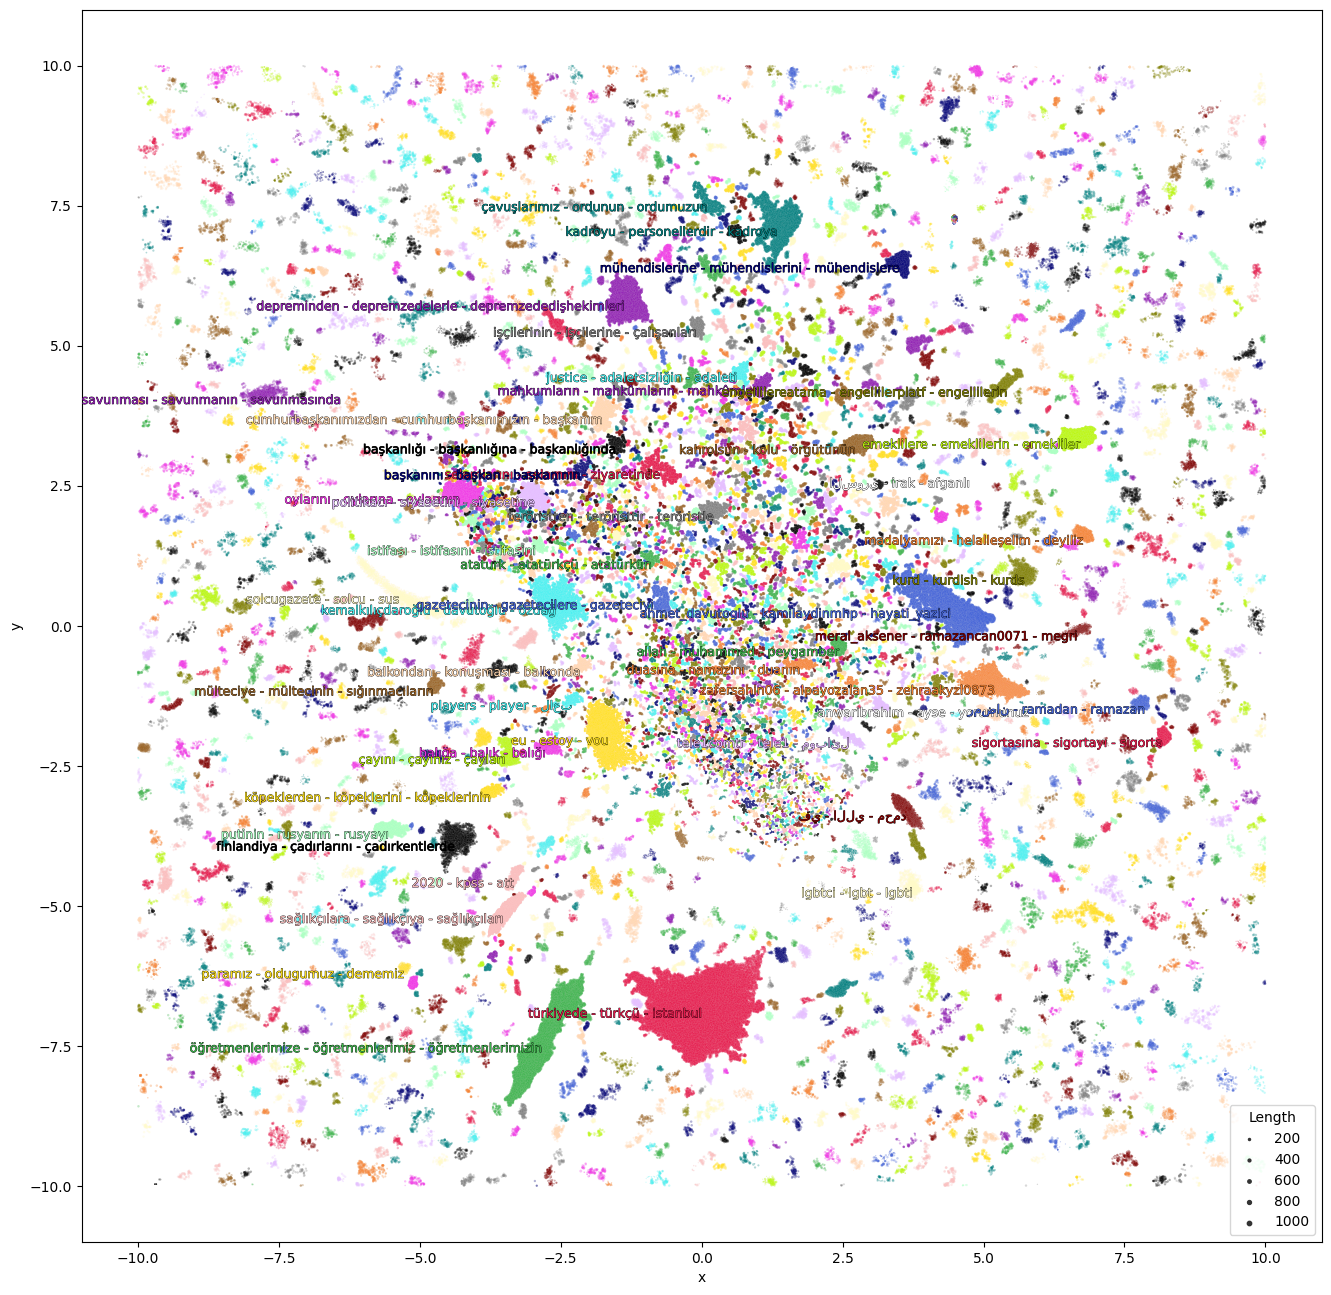

In [ ]:
import seaborn as sns
from matplotlib import pyplot as plt
from adjustText import adjust_text
import matplotlib.patheffects as pe

fig = plt.figure(figsize=(16, 16))
sns.scatterplot(data=df, x='x', y='y', c=df['Topic'].map(color_key), alpha=0.3, sizes=(0.4, 10), size="Length")

# Annotate top 50 topics
texts, xs, ys = [], [], []
for row in mean_df.iterrows():
  topic = row[1]["Topic"]
  name = " - ".join(list(zip(*topic_model.get_topic(int(topic))))[0][:3])

  if int(topic) <= 50:
    xs.append(row[1]["x"])
    ys.append(row[1]["y"])
    texts.append(plt.text(row[1]["x"], row[1]["y"], name, size=9, ha="center", color=color_key[str(int(topic))],
                          path_effects=[pe.withStroke(linewidth=0.5, foreground="black")]))

# Adjust annotations such that they do not overlap
adjust_text(texts, x=xs, y=ys, time_lim=1, force_text=(0.01, 0.02), force_static=(0.01, 0.02), force_pull=(0.5, 0.5))
plt.show()
# plt.savefig("visualization2.png", dpi=600)

In [ ]:
plt.savefig("/content/drive/MyDrive/data_tr/results/visualization6.png")

<Figure size 640x480 with 0 Axes>